***Preprocessing:Ambient RNA Decontamination and Doublet Removal***


In [1]:
install.packages("BiocManager")
BiocManager::install("Seurat")
BiocManager::install("SoupX")
BiocManager::install("scDblFinder")
BiocManager::install("glmGamPoi")
# Interoperability between Seurat and Scanpy via h5ad files
BiocManager::install("anndataR")
BiocManager::install("hdf5r")



The downloaded binary packages are in
	/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T//RtmpBFQnNA/downloaded_packages


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Warning message:
“package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'Seurat'”
Warning message in .available.both(repos, method, ...):
“Some listed binary packages have no source”
Old packages: 'assorthead', 'base64enc', 'BiocSingular', 'class', 'cluster',
  'colorspace', 'curl', 'edgeR', 'gdtools', 'gert', 'globals', 'igraph',
  'irlba', 'KernSmooth', 'lambda.r', 'lattice', 'listenv', 'MASS', 'mlr',
  'nlme', 'nnet', 'presto', 'roxygen2', 'S4Arrays', 'scDblFinder', 'sp',
  'SparseArray', 'spatial', 'spatstat.explore', 'spatstat.random', 'survival',
  'UCSC.utils', 'XML'

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", pack

package ‘scDblFinder’ successfully unpacked and SHA256 sums checked

The downloaded binary packages are in
	/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T//RtmpBFQnNA/downloaded_packages


Warning message in .available.both(repos, method, ...):
“Some listed binary packages have no source”
Old packages: 'assorthead', 'base64enc', 'BiocSingular', 'class', 'cluster',
  'colorspace', 'curl', 'edgeR', 'gdtools', 'gert', 'globals', 'igraph',
  'irlba', 'KernSmooth', 'lambda.r', 'lattice', 'listenv', 'MASS', 'mlr',
  'nlme', 'nnet', 'presto', 'roxygen2', 'S4Arrays', 'scDblFinder', 'sp',
  'SparseArray', 'spatial', 'spatstat.explore', 'spatstat.random', 'survival',
  'UCSC.utils', 'XML'

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Warning message:
“package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'glmGamPoi'”
Warning message in .available.both(repos, method, ...):
“Some listed binary packages have no 

In [2]:
library(Seurat) # Basic scRNA pipeline before SoupX
library(SoupX) # Ambient RNA removal
library(scDblFinder) # doublet finding
library(anndataR) # writing to Scanpy/Anndata compatible h5ad files
library(future)

# Set to higher values if the dataset exceeds the memory limit
options(future.globals.maxSize = 2 * 1024^3)
set.seed(7)




Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.6.0 but the current version is
4.6.1; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


v5.6 adds significant improvements in speed and efficiency, particularly for large datasets.
For more information, see https://satijalab.org/seurat/articles/announcements.


Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colA

In [3]:
tod_test <- Seurat::Read10X_h5(
  file.path("/Users/tank/Desktop", "single_cell_edna",
            "downloaded_results", "per_sample_outs", "counts",
            "sample_raw_feature_bc_matrix.h5")
)

class(tod_test)

[1] "dgCMatrix"
attr(,"package")
[1] "Matrix"

In [4]:
soupx_samples <- list()
clusters <- list()

  tod = Seurat::Read10X_h5(file.path("/Users/tank/Desktop","single_cell_edna","downloaded_results", "per_sample_outs", "counts","sample_raw_feature_bc_matrix.h5"))
  toc = Seurat::Read10X_h5(file.path("/Users/tank/Desktop","single_cell_edna","downloaded_results", "per_sample_outs", "counts","sample_filtered_feature_bc_matrix.h5"))
  filt_genes <- rownames(toc)
  tod <- tod[filt_genes, ]
  
  seurat <- CreateSeuratObject(counts=toc)
  seurat <- SCTransform(seurat)
  seurat <- RunPCA(seurat)
  seurat <- RunUMAP(seurat, dims=1:30)
  seurat <- FindNeighbors(seurat, dims=1:30)
  seurat <- FindClusters(seurat)

  
  meta <- seurat@meta.data
  sample_clusters <- setNames(meta$seurat_clusters, rownames(meta))


Running SCTransform on assay: RNA

vst.flavor='v2' set. Using model with fixed slope and excluding poisson genes.

Calculating cell attributes from input UMI matrix: log_umi

Variance stabilizing transformation of count matrix of size 15923 by 25189

Model formula is y ~ log_umi

Get Negative Binomial regression parameters per gene

Using 2000 genes, 5000 cells

Found 105 outliers - those will be ignored in fitting/regularization step


Skip calculation of full residual matrix

Calculating gene attributes

Wall clock passed: Time difference of 9.579313 secs

Set default assay to SCT

PC_ 1 
Positive:  Chil3, Ctss, Mpeg1, Gpnmb, Tyrobp, Ctsk, Slfn4, Plet1, Ctsd, Mrc1 
	   Lgals3, Ccl6, Fcer1g, Axl, Lpl, Psap, Sirpa, Atp6v0d2, Tgfbi, Cebpb 
	   Wfdc21, Itgb2, Cd68, Fth1, Car4, Clec4n, Slc7a2, F7, Wfdc17, Sgk1 
Negative:  Ager, Sftpa1, Egfl7, Igfbp7, Mgp, Cldn5, Inmt, Slc34a2, Cxcl15, Cbr2 
	   Vegfa, Col4a1, Sec14l3, Thbd, Hopx, Gsn, Calcrl, Col3a1, Sftpd, Col1a2 
	   Ace, Sparc, Shank3,

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 25189
Number of edges: 889691

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9197
Number of communities: 31
Elapsed time: 3 seconds


                              orig.ident nCount_RNA nFeature_RNA nCount_SCT
AAACAAGCAGATTGCAAGTAGGCT-1 SeuratProject       1528         1042       1718
AAACAAGCAGCCATAAAACGGGAA-1 SeuratProject       1000          794       1753
AAACAAGCAGCCTTCAACTTTAGG-1 SeuratProject       1445         1100       1698
AAACAAGCATACTTCAAGTAGGCT-1 SeuratProject      16373         4903       2426
AAACAAGCATATCGCTAACGGGAA-1 SeuratProject      20614         5840       2367
AAACAAGCATATCGCTACTTTAGG-1 SeuratProject      16177         5976       2382
                           nFeature_SCT SCT_snn_res.0.8 seurat_clusters
AAACAAGCAGATTGCAAGTAGGCT-1         1038               9               9
AAACAAGCAGCCATAAAACGGGAA-1          788               4               4
AAACAAGCAGCCTTCAACTTTAGG-1         1096               4               4
AAACAAGCATACTTCAAGTAGGCT-1         1512               1               1
AAACAAGCATATCGCTAACGGGAA-1         1592              21              21
AAACAAGCATATCGCTACTTTAGG-1         1

5437 genes passed tf-idf cut-off and 483 soup quantile filter.  Taking the top 100.

Using 738 independent estimates of rho.

Estimated global rho of 0.11

Warning message in sparseMatrix(i = out@i[w] + 1, j = out@j[w] + 1, x = out@x[w], :
“'giveCsparse' is deprecated; setting repr="T" for you”
Expanding counts from 31 clusters to 25189 cells.



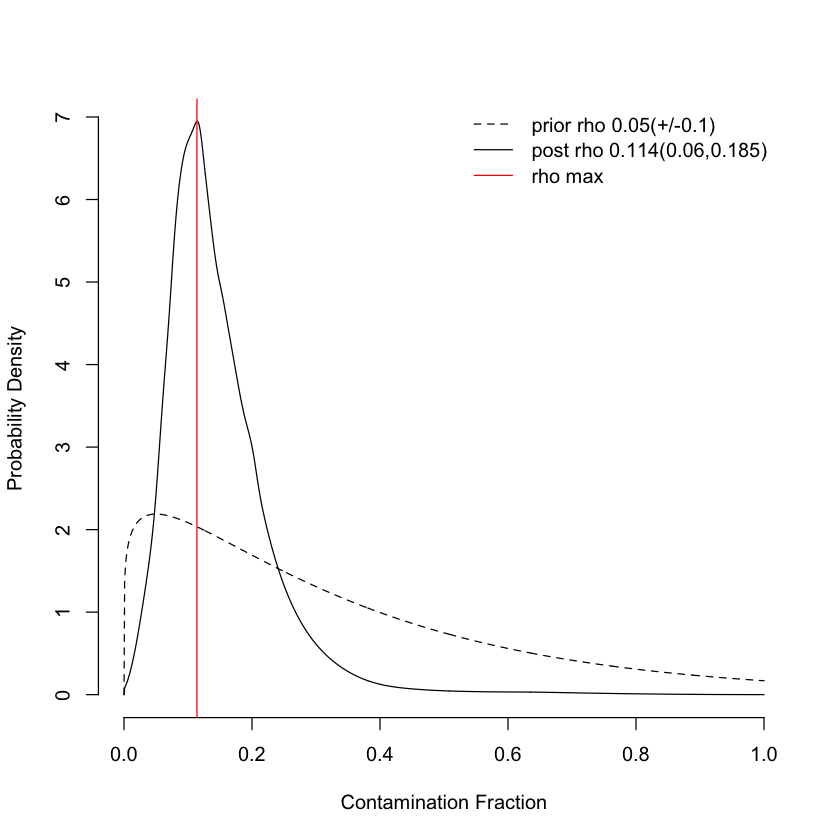

In [5]:

  sc <- SoupChannel(tod, toc)
  sc <- setClusters(sc, sample_clusters)
  sc <- setDR(sc, seurat@reductions$umap@cell.embeddings)
  print(head(meta))
  sc <- autoEstCont(sc)
  out <- adjustCounts(sc, roundToInt=TRUE)

  soupx_counts <- out



***Identify Doublets***

In [6]:
# soupX count matrix:
soupx_counts

# cluster labels:
sample_clusters

  [[ suppressing 32 column names ‘AAACAAGCAGATTGCAAGTAGGCT-1’, ‘AAACAAGCAGCCATAAAACGGGAA-1’, ‘AAACAAGCAGCCTTCAACTTTAGG-1’ ... ]]

  [[ suppressing 32 column names ‘AAACAAGCAGATTGCAAGTAGGCT-1’, ‘AAACAAGCAGCCATAAAACGGGAA-1’, ‘AAACAAGCAGCCTTCAACTTTAGG-1’ ... ]]

  [[ suppressing 32 column names ‘AAACAAGCAGATTGCAAGTAGGCT-1’, ‘AAACAAGCAGCCATAAAACGGGAA-1’, ‘AAACAAGCAGCCTTCAACTTTAGG-1’ ... ]]



19384 x 25189 sparse Matrix of class "dgCMatrix"
                                                                                             
Xkr4       . . .   .   .  . . .   .  .  . . .  .  . . . .  . .   . . .  .  .  . . .  . .  . .
Rp1        . . .   .   .  0 . .   .  .  . . .  .  . . . .  . .   . . .  .  .  . . .  0 .  . .
Sox17      . . .   .   .  1 . .   .  .  3 . .  .  . . . .  2 .   . . .  .  .  4 . .  0 .  . .
Lypla1     . . 1   .   1  . . .   .  .  . . .  .  . . . .  . 2   3 . .  .  3  . . .  . .  . .
Tcea1      . . .   1   1  . . .   3  .  . . .  1  . . . .  . .   1 . .  1  2  . . .  1 .  . .
Rgs20      . . .   .   .  . . .   .  .  . . .  .  . . . .  . .   . . .  .  .  . . .  . .  . .
Atp6v1h    0 1 .   1   1  2 . .   5  1  . . .  .  . . 1 .  . .   2 . 2  .  1  3 . .  . .  2 1
Oprk1      . . .   .   .  . . .   .  .  . . .  .  . . . .  . .   . . .  .  .  . . .  . .  . .
Npbwr1     . . .   .   .  . . .   .  .  . . .  .  . . . .  . .   . . .  .  .  . . .  . .  . .
Rb1cc1     

AAACAAGCAGATTGCAAGTAGGCT-1 AAACAAGCAGCCATAAAACGGGAA-1 
                         9                          4 
AAACAAGCAGCCTTCAACTTTAGG-1 AAACAAGCATACTTCAAGTAGGCT-1 
                         4                          1 
AAACAAGCATATCGCTAACGGGAA-1 AAACAAGCATATCGCTACTTTAGG-1 
                        21                         10 
AAACAAGCATCCAAGAACTTTAGG-1 AAACAAGCATCGATAGATGTTGAC-1 
                         2                          0 
AAACAAGCATTCAACCATGTTGAC-1 AAACCAATCACCTAATAACGGGAA-1 
                         1                          6 
AAACCAATCAGGCATGACTTTAGG-1 AAACCAATCATTATGCAACGGGAA-1 
                         3                          2 
AAACCAATCCCATAGCACTTTAGG-1 AAACCAATCCTAAGGGAGTAGGCT-1 
                         2                          5 
AAACCAATCCTAATCGAGTAGGCT-1 AAACCAATCCTTTCTAATGTTGAC-1 
                        12                          2 
AAACCAATCGAAGGCCATGTTGAC-1 AAACCAATCGGTTCCGATGTTGAC-1 
                         2                         27 
AAACCAATCGTCCATAATGTTGAC-1 AAACCAATCTATGCATACTTTAGG-1 
                         3                         28 
AAACCAATCTGTCAATAGTAGGCT-1 AAACCAATCTTTAAGCAACGGGAA-1 
                         1                         28 
AAACCAGGTACGTTACAGTAGGCT-1 AAACCAGGTCACAGAAAGTAGGCT-1 
                        17                          9 
AAACCAGGTGCTGATTAGTAGGCT-1 AAACCAGGTGTTTGGTAGTAGGCT-1 
                        10                          3 
AAACCAGGTTAAGCCTATGTTGAC-1 AAACCAGGTTCGAATCAGTAGGCT-1 
                        17                          8 
AAACCAGGTTGCACTGACTTTAGG-1 AAACCAGGTTTATGGCAACGGGAA-1 
                         3                         24 
AAACCAGGTTTCCAAAAGTAGGCT-1 AAACCGGTCAGCGGGTACTTTAGG-1 
                        10                          2 
AAACCGGTCAGCGGGTAGTAGGCT-1 AAACCGGTCAGGCTGAAGTAGGCT-1 
                        13                          9 
AAACCGGTCATCAGCCAACGGGAA-1 AAACCGGTCATGCCTAAGTAGGCT-1 
                        11                         10 
AAACCGGTCATGCCTAATGTTGAC-1 AAACCGGTCCAGAACGAACGGGAA-1 
                        14                          9 
AAACCGGTCCAGAACGACTTTAGG-1 AAACCGGTCCATAAAGACTTTAGG-1 
                         1                          1 
AAACCGGTCCGGATAGACTTTAGG-1 AAACCGGTCGATTATCACTTTAGG-1 
                        17                         22 
AAACCGGTCTGGAACGAGTAGGCT-1 AAACCGGTCTGTGATTAACGGGAA-1 
                        14                          0 
AAACGGGCAACTTCGTATGTTGAC-1 AAACGGGCAATGGCCGAGTAGGCT-1 
                         4                         13 
AAACGGGCAATTGCGAACTTTAGG-1 AAACGGGCACAATAGTACTTTAGG-1 
                         0                         18 
AAACGGGCATAGCCTTAGTAGGCT-1 AAACGGGCATATTTCGATGTTGAC-1 
                        17                          0 
AAACGGGCATTCCTGGACTTTAGG-1 AAACGGGCATTCCTGGATGTTGAC-1 
                         3                         16 
AAACGGGCATTTCGCGAGTAGGCT-1 AAACGGGCATTTCGCGATGTTGAC-1 
                         2                          1 
AAACGTTCAAAGGTAAACTTTAGG-1 AAACGTTCAAATAAGGAGTAGGCT-1 
                         6                         14 
AAACGTTCAAATGACTAACGGGAA-1 AAACGTTCAACAAGCCATGTTGAC-1 
                         5                          4 
AAACGTTCAACCGTGGACTTTAGG-1 AAACGTTCAACCGTGGATGTTGAC-1 
                        13                          9 
AAACGTTCAAGAACAAAACGGGAA-1 AAACGTTCAAGCCACGACTTTAGG-1 
                         4                          2 
AAACGTTCAATAACCGATGTTGAC-1 AAACGTTCACAATACGAGTAGGCT-1 
                        22                          0 
AAACGTTCACCGTTTGACTTTAGG-1 AAACGTTCACCGTTTGATGTTGAC-1 
                         2                          4 
AAACGTTCACTAACGAATGTTGAC-1 AAACGTTCAGCCAGCAACTTTAGG-1 
                         0                          6 
AAACGTTCAGCCAGCAAGTAGGCT-1 AAACGTTCAGCCCTTAACTTTAGG-1 
                        15                          2 
AAACGTTCAGCCTGAGAACGGGAA-1 AAACGTTCATTGGACAAGTAGGCT-1 
                         8                          4 
AAACGTTCATTGTGTCAGTAGGCT-1 AAACTGGGTCACA

In [7]:
# 1. Create a SingleCellExperiment object
sce <- SingleCellExperiment(
  assays = list(counts = soupx_counts)
)

# 2. Detect doublets
sce <- scDblFinder(
  sce,
  clusters = sample_clusters
)

# 3. Store the result
scdblfinder_sce <- sce

Warning message in scDblFinder(sce, clusters = sample_clusters):
“You are trying to run scDblFinder on a very large number of cells. If these are from different captures, please specify this using the `samples` argument.TRUE”
31 clusters

Creating ~20152 artificial doublets...

Dimensional reduction

Evaluating kNN...

Training model...

iter=0, 3432 cells excluded from training.

iter=1, 3617 cells excluded from training.

iter=2, 3641 cells excluded from training.

Threshold found:0.458

3970 (15.8%) doublets called



In [9]:
output_dir <- file.path(
  path.expand("~/Desktop"),
  "single_cell_edna",
  "output"
)

In [10]:
write_h5ad(scdblfinder_sce, file.path(output_dir, "edna.h5ad"))
